IMPORTING ALL THE LIBRARIES

In [ ]:
import pandas as pd
import numpy as np
import datetime
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor


# 1. LOAD DATASET

In [ ]:
csv_filename = "Training_Data_for_ML _UPDATED.csv"

df = pd.read_csv(csv_filename)

print("Dataset Loaded Successfully")
print("Rows:", len(df))



Dataset Loaded Successfully
Rows: 450


 2. DATE FEATURE ENGINEERING

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])

df['day'] = df['Date'].dt.day
df['month'] = df['Date'].dt.month
df['weekday'] = df['Date'].dt.weekday


3. DEFINE FEATURES AND TARGET

In [ ]:
target = "Daily_Usage_m3"

features = [
    'Zone',
    'Labor_Count',
    'Weather_Rain',
    'Truck_Travel_Min',
    'Concrete_Quality',
    'day',
    'month',
    'weekday'
]

X = df[features]
y = df[target]

4. TRAIN TEST SPLIT

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

5. DATA PREPROCESSING

In [ ]:
categorical_cols = ['Zone', 'Concrete_Quality']
numeric_cols = ['Labor_Count', 'Weather_Rain', 'Truck_Travel_Min', 'day', 'month', 'weekday']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

6. DEFINE MODELS

In [ ]:
models = {
    "RandomForest": RandomForestRegressor(n_estimators=120, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=120, learning_rate=0.08),
    "LightGBM": LGBMRegressor(n_estimators=120)
}

7. TRAIN AND COMPARE MODELS

In [ ]:
results = {}
trained_models = {}

print("\nTraining Models...\n")

for name, reg in models.items():

    model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', reg)
    ])

    model.fit(X_train, y_train)

    preds = model.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    results[name] = r2
    trained_models[name] = model

    print(f"{name} → R2 Score: {r2:.3f} | MAE: {mae:.2f}")



Training Models...

RandomForest → R2 Score: 0.969 | MAE: 0.04
XGBoost → R2 Score: 0.962 | MAE: 0.05
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000262 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 108
[LightGBM] [Info] Number of data points in the train set: 360, number of used features: 11
[LightGBM] [Info] Start training from score 0.379750
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with p

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


8. SELECT BEST MODEL

In [ ]:
best_model_name = max(results, key=results.get)
best_model = trained_models[best_model_name]

print("\nBest Model Selected:", best_model_name)


Best Model Selected: RandomForest


9. MODEL COMPARISON CHART

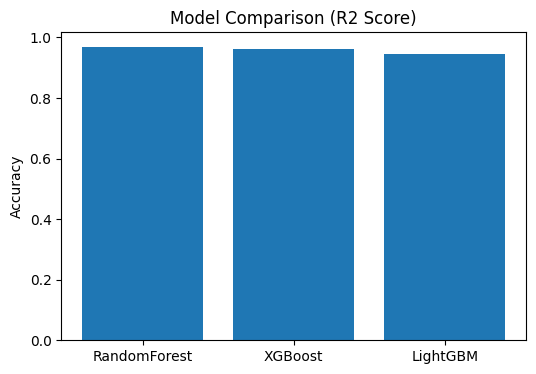

In [ ]:
plt.figure(figsize=(6,4))
plt.bar(results.keys(), results.values())
plt.title("Model Comparison (R2 Score)")
plt.ylabel("Accuracy")
plt.show()

10. FORECAST NEXT 7 DAYS

In [ ]:
print("\nForecasting Next 7 Days")
print("-"*60)

last_date = pd.to_datetime(df['Date'].max())

next_days = [last_date + datetime.timedelta(days=i) for i in range(1,8)]

future_data = pd.DataFrame({
    'Date': next_days,
   # 'Zone': ['Zone A','Zone B','Zone C','Zone D','Zone A','Zone B','Zone C'],
    'Zone': ['Foundation','Zone A','Zone B','Foundation','Zone A','Zone B','Foundation'],
    'Labor_Count': [25,28,12,20,30,22,10],
    'Weather_Rain': [0,0,1,0,0,0,0],
    'Truck_Travel_Min': [30,35,90,40,30,25,20],
    'Concrete_Quality': ['GOOD','GOOD','REJECTED','GOOD','GOOD','GOOD','GOOD']
})


future_data['day'] = future_data['Date'].dt.day
future_data['month'] = future_data['Date'].dt.month
future_data['weekday'] = future_data['Date'].dt.weekday


future_preds = best_model.predict(future_data[features])


print(f"{'Date':<12} | {'Zone':<8} | {'Labor':<6} | {'Prediction (m3)'}")
print("-"*60)

for i, row in future_data.iterrows():

    date_str = row['Date'].strftime('%Y-%m-%d')
    pred_val = future_preds[i]

    print(f"{date_str:<12} | {row['Zone']:<8} | {row['Labor_Count']:<6} | {pred_val:.2f}")


print("-"*60)
print("Total Concrete Needed:", round(sum(future_preds),2), "m³")


Forecasting Next 7 Days
------------------------------------------------------------
Date         | Zone     | Labor  | Prediction (m3)
------------------------------------------------------------
2025-03-31   | Foundation | 25     | 1.02
2025-04-01   | Zone A   | 28     | 0.25
2025-04-02   | Zone B   | 12     | 0.01
2025-04-03   | Foundation | 20     | 0.82
2025-04-04   | Zone A   | 30     | 0.26
2025-04-05   | Zone B   | 22     | 0.23
2025-04-06   | Foundation | 10     | 0.74
------------------------------------------------------------
Total Concrete Needed: 3.33 m³
